# PerfectPetClub – Customer Churn Prediction

## Machine Learning Overview

This notebook focuses on developing a machine learning pipeline
to identify customers who may cancel their subscriptions.

The prepared dataset from the ETL pipeline is used to perform
feature preparation, model training, hyperparameter tuning,
evaluation, and customer prediction.

PySpark ML is used for model development and training.

### Machine Learning Workflow

1. Environment and dependency setup
2. Library imports and Spark initialisation
3. Dataset loading
4. Feature selection and data preparation
5. Model training and baseline comparison
6. Hyperparameter tuning
7. Model evaluation
8. Customer prediction and risk classification

## 1. Environment and Dependency Setup

Install and configure the required dependencies for running the
PySpark machine learning pipeline.

This includes setting up PySpark and the Java environment required
by Apache Spark.

In [1]:
%pip install pyspark scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
conda install -c conda-forge openjdk=17 -y

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.10.0

Please update conda by running

    $ conda update -n base -c defaults conda



# All requested packages already installed.


Note: you may need to restart the kernel to use updated packages.


In [3]:
!conda install -c conda-forge openjdk=17 -y

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.10.0

Please update conda by running

    $ conda update -n base -c defaults conda



# All requested packages already installed.



In [4]:
!java -version

The operation couldn’t be completed. Unable to locate a Java Runtime.
Please visit http://www.java.com for information on installing Java.



In [5]:
import os, sys, glob

# Locate Java inside Anaconda/Conda environment
conda_prefix = sys.prefix
java_candidates = glob.glob(os.path.join(conda_prefix, "**", "bin", "java"), recursive=True)
print("Found Java binaries:", java_candidates)

if java_candidates:
    java_bin_dir = os.path.dirname(java_candidates[0])
    java_home = os.path.dirname(java_bin_dir)
    os.environ["JAVA_HOME"] = java_home
    os.environ["PATH"] = java_bin_dir + os.pathsep + os.environ.get("PATH", "")
    print("Set JAVA_HOME =", java_home)
    !java -version
else:
    print("Not found in sys.prefix — installing via conda...")
    !conda install -c conda-forge openjdk=17 -y

Found Java binaries: ['/opt/anaconda3/python.app/Contents/lib/jvm/bin/java', '/opt/anaconda3/pkgs/openjdk-17.0.18-h258754b_0/lib/jvm/bin/java', '/opt/anaconda3/lib/jvm/bin/java']
Set JAVA_HOME = /opt/anaconda3/python.app/Contents/lib/jvm
openjdk version "17.0.18" 2026-01-20 LTS
OpenJDK Runtime Environment Zulu17.64+17-CA (build 17.0.18+8-LTS)
OpenJDK 64-Bit Server VM Zulu17.64+17-CA (build 17.0.18+8-LTS, mixed mode, sharing)


In [6]:
import os, sys, glob

java_candidates = glob.glob(os.path.join(sys.prefix, "**", "bin", "java"), recursive=True)
if java_candidates:
    java_bin_dir = os.path.dirname(java_candidates[0])
    os.environ["JAVA_HOME"] = os.path.dirname(java_bin_dir)
    os.environ["PATH"] = java_bin_dir + os.pathsep + os.environ.get("PATH", "")

In [7]:
import os, sys, glob, subprocess

# 1. Search everywhere inside /opt/anaconda3 for a real java binary
hits = glob.glob("/opt/anaconda3/**/bin/java", recursive=True)
print("Existing Java binaries in anaconda3:", hits)

# 2. If none exist, install openjdk=17 directly into /opt/anaconda3
if not hits:
    print("Installing OpenJDK 17 into Anaconda... please wait ~30 seconds...")
    subprocess.run([os.path.join(sys.prefix, "bin", "conda"), "install", "-c", "conda-forge", "openjdk=17", "-y"], check=True)
    hits = glob.glob("/opt/anaconda3/**/bin/java", recursive=True)
    print("After install, Java binaries:", hits)

# 3. Point JAVA_HOME and PATH to the first real java binary found
java_bin = hits[0]
java_home = os.path.dirname(os.path.dirname(java_bin))
os.environ["JAVA_HOME"] = java_home
os.environ["PATH"] = os.path.dirname(java_bin) + os.pathsep + os.environ.get("PATH", "")

print("JAVA_HOME set to:", os.environ["JAVA_HOME"])
!java -version

Existing Java binaries in anaconda3: ['/opt/anaconda3/python.app/Contents/lib/jvm/bin/java', '/opt/anaconda3/pkgs/openjdk-17.0.18-h258754b_0/lib/jvm/bin/java', '/opt/anaconda3/lib/jvm/bin/java']
JAVA_HOME set to: /opt/anaconda3/python.app/Contents/lib/jvm
openjdk version "17.0.18" 2026-01-20 LTS
OpenJDK Runtime Environment Zulu17.64+17-CA (build 17.0.18+8-LTS)
OpenJDK 64-Bit Server VM Zulu17.64+17-CA (build 17.0.18+8-LTS, mixed mode, sharing)


## 2. Library Imports and Spark Initialisation

Import the required libraries and initialise the Spark session.

Configure the Spark environment and logging settings required
for data processing and machine learning.

In [8]:
import os
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure Spark uses Anaconda's OpenJDK 17 runtime
os.environ["JAVA_HOME"] = "/opt/anaconda3/lib/jvm"
os.environ["PATH"] = "/opt/anaconda3/lib/jvm/bin:" + os.environ.get("PATH", "")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, classification_report, auc

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S"
)
logger = logging.getLogger("PerfectPetClub_PySpark_ML")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

spark = (
    SparkSession.builder
    .appName("PerfectPetClub_Churn_ML")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
logger.info(f"SparkSession initialized (Spark v{spark.version}).")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/12 13:57:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
2026-11-12 13:57:13 | INFO     | SparkSession initialized (Spark v4.3.0).


## 3. Loading and Inspecting the ETL Dataset

Load the consolidated customer-level dataset generated by the
ETL pipeline.

Inspect the dataset to understand its structure, features,
data types, and target variable before preparing it for modelling.

In [9]:
PARQUET_PATH = "customer_churn.parquet"
assert os.path.exists(PARQUET_PATH), f"Missing {PARQUET_PATH}! Run ETL_Pipeline.ipynb first."

df_spark = spark.read.parquet(PARQUET_PATH)
logger.info(f"Loaded {PARQUET_PATH}: {df_spark.count()} rows, {len(df_spark.columns)} columns.")

df_spark.printSchema()
df_spark.groupBy("churn").count().withColumn("pct", F.round(F.col("count") / df_spark.count() * 100, 2)).show()

2026-11-12 13:57:14 | INFO     | Loaded customer_churn.parquet: 221 rows, 76 columns.


root
 |-- customer_id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- email: string (nullable = true)
 |-- county: string (nullable = true)
 |-- postcode: string (nullable = true)
 |-- subscription_tier: string (nullable = true)
 |-- delivery_service: string (nullable = true)
 |-- subscription_monthly_fee_gbp: double (nullable = true)
 |-- active_tenure_days: double (nullable = true)
 |-- active_tenure_months: double (nullable = true)
 |-- churn: long (nullable = true)
 |-- total_orders: long (nullable = true)
 |-- physical_orders: long (nullable = true)
 |-- subscription_renewals: long (nullable = true)
 |-- total_spend_gbp: double (nullable = true)
 |-- avg_order_value_gbp: double (nullable = true)
 |-- std_order_value_gbp: double (nullable = true)
 |-- late_deliveries: double (nullable = true)
 |-- late_delivery_rate: double (nullable = true)
 |-- avg_delivery_delay_hours: double (nullable = true)
 |-- max_delivery_delay_hours: double (nullable = true)
 |-- gw_share

## 4. Feature Selection and Data Preparation

Prepare the dataset for machine learning by selecting relevant
features and excluding unnecessary or unsuitable columns.

This stage also handles class imbalance and splits the dataset
into training and testing sets for model development and evaluation.

In [10]:
EXCLUDED_COLS = {
    "customer_id", "name", "email", "county", "postcode", "churn",
    "active_tenure_days", "active_tenure_months",
    "total_orders", "physical_orders", "subscription_renewals",
    "total_spend_gbp", "total_physical_units",
    "review_count", "low_rating_count", "late_deliveries",
    "crm_total_contacts", "crm_complaints", "crm_queries",
    "crm_email_count", "crm_phone_count", "crm_chat_count",
    "total_logins", "unique_ips"
}

categorical_cols = ["subscription_tier", "delivery_service", "primary_pet_segment"]
numeric_cols = [c for c in df_spark.columns if c not in EXCLUDED_COLS and c not in categorical_cols]

logger.info(f"Selected {len(categorical_cols)} categorical and {len(numeric_cols)} leakage-safe numeric features.")
print("Numeric Features:", numeric_cols)

# Inverse class-frequency weights (38.9% churn vs 61.1% retained)
total_rows = df_spark.count()
churn_count = df_spark.filter(F.col("churn") == 1).count()
retain_count = total_rows - churn_count
w_churn = total_rows / (2.0 * churn_count)
w_retain = total_rows / (2.0 * retain_count)

df_weighted = df_spark.withColumn(
    "classWeight",
    F.when(F.col("churn") == 1, F.lit(w_churn)).otherwise(F.lit(w_retain))
)

# Stratified 80/20 Train/Test Split
train_df = df_weighted.stat.sampleBy("churn", fractions={0: 0.80, 1: 0.80}, seed=42)
test_df = df_weighted.join(train_df.select("customer_id"), on="customer_id", how="left_anti")

logger.info(f"Stratified split complete -> Train: {train_df.count()} rows | Test: {test_df.count()} rows")
train_df.groupBy("churn").count().show()
test_df.groupBy("churn").count().show()

2026-11-12 13:57:15 | INFO     | Selected 3 categorical and 49 leakage-safe numeric features.


Numeric Features: ['subscription_monthly_fee_gbp', 'avg_order_value_gbp', 'std_order_value_gbp', 'late_delivery_rate', 'avg_delivery_delay_hours', 'max_delivery_delay_hours', 'gw_share_cardpay', 'gw_share_directdebit', 'gw_share_paypool', 'unique_products_bought', 'unique_categories_bought', 'avg_star_rating', 'min_star_rating', 'low_rating_ratio', 'crm_complaint_ratio', 'crm_high_touch_channel_share', 'weekend_login_ratio', 'evening_login_ratio', 'device_share_desktop', 'device_share_mobile', 'device_share_tablet', 'nps_recommend', 'satisfaction_score', 'online_comparison_freq', 'income_midpoint_k', 'composite_sentiment_score', 'nps_satisfaction_gap', 'is_nps_detractor', 'is_nps_promoter', 'price_sensitivity_risk', 'orders_last_30d', 'orders_prev_30d', 'order_velocity_change', 'order_velocity_ratio', 'logins_last_30d', 'logins_prev_30d', 'login_velocity_change', 'login_velocity_ratio', 'complaints_last_30d', 'complaints_prev_30d', 'complaint_velocity_change', 'orders_per_month', 'phys

2026-11-12 13:57:15 | INFO     | Stratified split complete -> Train: 187 rows | Test: 34 rows


+-----+-----+
|churn|count|
+-----+-----+
|    1|   69|
|    0|  118|
+-----+-----+

+-----+-----+
|churn|count|
+-----+-----+
|    0|   17|
|    1|   17|
+-----+-----+



## 5. PySpark ML Pipeline and Baseline Models

Build the machine learning pipeline using PySpark ML components.

Train and evaluate baseline classification models to establish
initial performance results.

Compare the models using appropriate classification metrics
to identify promising candidates for further tuning.

In [11]:
def build_feature_stages(cat_cols: list, num_cols: list) -> list:
    """Constructs reusable PySpark ML preprocessing stages."""
    indexers = [
        StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
        for c in cat_cols
    ]
    encoders = [
        OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_ohe")
        for c in cat_cols
    ]
    assembler_inputs = [f"{c}_ohe" for c in cat_cols] + num_cols
    assembler = VectorAssembler(inputCols=assembler_inputs, outputCol="raw_features", handleInvalid="keep")
    scaler = StandardScaler(inputCol="raw_features", outputCol="features", withStd=True, withMean=True)
    return indexers + encoders + [assembler, scaler]


feature_stages = build_feature_stages(categorical_cols, numeric_cols)

auc_eval = BinaryClassificationEvaluator(labelCol="churn", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_eval = BinaryClassificationEvaluator(labelCol="churn", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
f1_eval = MulticlassClassificationEvaluator(labelCol="churn", predictionCol="prediction", metricName="f1")
acc_eval = MulticlassClassificationEvaluator(labelCol="churn", predictionCol="prediction", metricName="accuracy")
prec_eval = MulticlassClassificationEvaluator(labelCol="churn", predictionCol="prediction", metricName="weightedPrecision")
rec_eval = MulticlassClassificationEvaluator(labelCol="churn", predictionCol="prediction", metricName="weightedRecall")


def evaluate_predictions(pred_df, model_name: str) -> dict:
    """Computes comprehensive classification metrics on a PySpark prediction DataFrame."""
    return {
        "Model": model_name,
        "ROC_AUC": round(auc_eval.evaluate(pred_df), 4),
        "PR_AUC": round(pr_eval.evaluate(pred_df), 4),
        "F1_Score": round(f1_eval.evaluate(pred_df), 4),
        "Accuracy": round(acc_eval.evaluate(pred_df), 4),
        "Precision": round(prec_eval.evaluate(pred_df), 4),
        "Recall": round(rec_eval.evaluate(pred_df), 4)
    }


models = {
    "Logistic Regression (Baseline)": LogisticRegression(
        featuresCol="features", labelCol="churn", weightCol="classWeight", maxIter=100
    ),
    "Random Forest (Baseline)": RandomForestClassifier(
        featuresCol="features", labelCol="churn", weightCol="classWeight", numTrees=100, maxDepth=6, seed=42
    ),
    "Gradient Boosted Trees (Baseline)": GBTClassifier(
        featuresCol="features", labelCol="churn", weightCol="classWeight", maxIter=50, maxDepth=4, seed=42
    )
}

baseline_results = []
fitted_baselines = {}

for name, clf in models.items():
    pipe = Pipeline(stages=feature_stages + [clf])
    fitted = pipe.fit(train_df)
    preds = fitted.transform(test_df)
    metrics = evaluate_predictions(preds, name)
    baseline_results.append(metrics)
    fitted_baselines[name] = (fitted, preds)
    logger.info(f"{name:<34} | ROC-AUC: {metrics['ROC_AUC']:.4f} | F1: {metrics['F1_Score']:.4f} | Acc: {metrics['Accuracy']:.4f}")

display(pd.DataFrame(baseline_results))

26/11/12 13:57:16 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
2026-11-12 13:57:18 | INFO     | Logistic Regression (Baseline)     | ROC-AUC: 0.7785 | F1: 0.7351 | Acc: 0.7353
2026-11-12 13:57:20 | INFO     | Random Forest (Baseline)           | ROC-AUC: 0.9308 | F1: 0.8518 | Acc: 0.8529
2026-11-12 13:57:24 | INFO     | Gradient Boosted Trees (Baseline)  | ROC-AUC: 0.8201 | F1: 0.7332 | Acc: 0.7353


,Model,ROC_AUC,PR_AUC,F1_Score,Accuracy,Precision,Recall
0,Logistic Regression (Baseline),0.7785,0.8239,0.7351,0.7353,0.7361,0.7353
1,Random Forest (Baseline),0.9308,0.9480,0.8518,0.8529,0.8643,0.8529
2,Gradient Boosted Trees (Baseline),0.8201,0.8535,0.7332,0.7353,0.7429,0.7353


## 6. Hyperparameter Tuning and Model Comparison

Improve the performance of the selected candidate models through
hyperparameter tuning and cross-validation.

Compare the tuned models to determine which provides the most
suitable performance for the customer churn prediction task.

In [12]:
# 1. Tune Random Forest
rf_clf = RandomForestClassifier(featuresCol="features", labelCol="churn", weightCol="classWeight", seed=42)
rf_pipe = Pipeline(stages=feature_stages + [rf_clf])
rf_grid = (
    ParamGridBuilder()
    .addGrid(rf_clf.numTrees, [100, 200])
    .addGrid(rf_clf.maxDepth, [4, 6, 8])
    .addGrid(rf_clf.minInstancesPerNode, [1, 3])
    .build()
)
rf_cv = CrossValidator(estimator=rf_pipe, estimatorParamMaps=rf_grid, evaluator=auc_eval, numFolds=5, seed=42)
rf_cv_model = rf_cv.fit(train_df)
rf_tuned_preds = rf_cv_model.transform(test_df)

# 2. Tune Gradient Boosted Trees
gbt_clf = GBTClassifier(featuresCol="features", labelCol="churn", weightCol="classWeight", seed=42)
gbt_pipe = Pipeline(stages=feature_stages + [gbt_clf])
gbt_grid = (
    ParamGridBuilder()
    .addGrid(gbt_clf.maxIter, [40, 80])
    .addGrid(gbt_clf.maxDepth, [3, 4])
    .addGrid(gbt_clf.stepSize, [0.05, 0.1])
    .build()
)
gbt_cv = CrossValidator(estimator=gbt_pipe, estimatorParamMaps=gbt_grid, evaluator=auc_eval, numFolds=5, seed=42)
gbt_cv_model = gbt_cv.fit(train_df)
gbt_tuned_preds = gbt_cv_model.transform(test_df)

# 3. Tune Logistic Regression
lr_clf = LogisticRegression(featuresCol="features", labelCol="churn", weightCol="classWeight", maxIter=200)
lr_pipe = Pipeline(stages=feature_stages + [lr_clf])
lr_grid = (
    ParamGridBuilder()
    .addGrid(lr_clf.regParam, [0.01, 0.1, 0.5])
    .addGrid(lr_clf.elasticNetParam, [0.0, 0.5, 1.0])
    .build()
)
lr_cv = CrossValidator(estimator=lr_pipe, estimatorParamMaps=lr_grid, evaluator=auc_eval, numFolds=5, seed=42)
lr_cv_model = lr_cv.fit(train_df)
lr_tuned_preds = lr_cv_model.transform(test_df)

all_results = baseline_results + [
    evaluate_predictions(lr_tuned_preds, "Logistic Regression (Tuned)"),
    evaluate_predictions(rf_tuned_preds, "Random Forest (Tuned)"),
    evaluate_predictions(gbt_tuned_preds, "Gradient Boosted Trees (Tuned)")
]

comparison_df = pd.DataFrame(all_results).sort_values(by="ROC_AUC", ascending=False).reset_index(drop=True)
display(comparison_df)

best_rf_stage = rf_cv_model.bestModel.stages[-1]
logger.info(
    f"Best Random Forest Params -> numTrees={best_rf_stage.getNumTrees}, "
    f"maxDepth={best_rf_stage.getOrDefault('maxDepth')}, "
    f"minInstancesPerNode={best_rf_stage.getOrDefault('minInstancesPerNode')}"
)

26/11/12 13:57:32 WARN DAGScheduler: Broadcasting large task binary with size 1114.2 KiB
26/11/12 13:57:35 WARN DAGScheduler: Broadcasting large task binary with size 1217.5 KiB
26/11/12 13:57:36 WARN DAGScheduler: Broadcasting large task binary with size 1032.3 KiB
26/11/12 13:57:44 WARN DAGScheduler: Broadcasting large task binary with size 1108.4 KiB
26/11/12 13:57:46 WARN DAGScheduler: Broadcasting large task binary with size 1032.3 KiB
26/11/12 13:57:46 WARN DAGScheduler: Broadcasting large task binary with size 1224.6 KiB
26/11/12 13:57:47 WARN DAGScheduler: Broadcasting large task binary with size 1039.7 KiB
26/11/12 13:57:55 WARN DAGScheduler: Broadcasting large task binary with size 1108.9 KiB
26/11/12 13:57:57 WARN DAGScheduler: Broadcasting large task binary with size 1212.6 KiB
26/11/12 13:57:58 WARN DAGScheduler: Broadcasting large task binary with size 1010.5 KiB
26/11/12 13:58:06 WARN DAGScheduler: Broadcasting large task binary with size 1112.1 KiB
26/11/12 13:58:08 WAR

,Model,ROC_AUC,PR_AUC,F1_Score,Accuracy,Precision,Recall
0,Random Forest (Baseline),0.9308,0.9480,0.8518,0.8529,0.8643,0.8529
1,Random Forest (Tuned),0.9308,0.9524,0.9111,0.9118,0.9250,0.9118
2,Logistic Regression (Tuned),0.8997,0.9007,0.8528,0.8529,0.8542,0.8529
3,Gradient Boosted Trees (Tuned),0.8581,0.8786,0.7647,0.7647,0.7647,0.7647
4,Gradient Boosted Trees (Baseline),0.8201,0.8535,0.7332,0.7353,0.7429,0.7353
5,Logistic Regression (Baseline),0.7785,0.8239,0.7351,0.7353,0.7361,0.7353


2026-11-12 14:01:09 | INFO     | Best Random Forest Params -> numTrees=100, maxDepth=8, minInstancesPerNode=1


## 7. Model Evaluation and Visualisation

Evaluate the trained models using classification performance
metrics and visualisations.

This stage examines model performance through confusion matrices,
ROC curves, precision-recall curves, and feature importance.

The evaluation results help assess the strengths and limitations
of the developed models.

,Feature,Importance
0,login_velocity_ratio,0.106295
1,login_velocity_change,0.104231
2,order_velocity_ratio,0.063962
3,logins_prev_30d,0.058921
4,order_velocity_change,0.047427
5,orders_prev_30d,0.040865
6,nps_satisfaction_gap,0.030145
7,logins_per_month,0.030002
8,avg_order_value_gbp,0.028770
9,logins_last_30d,0.028282


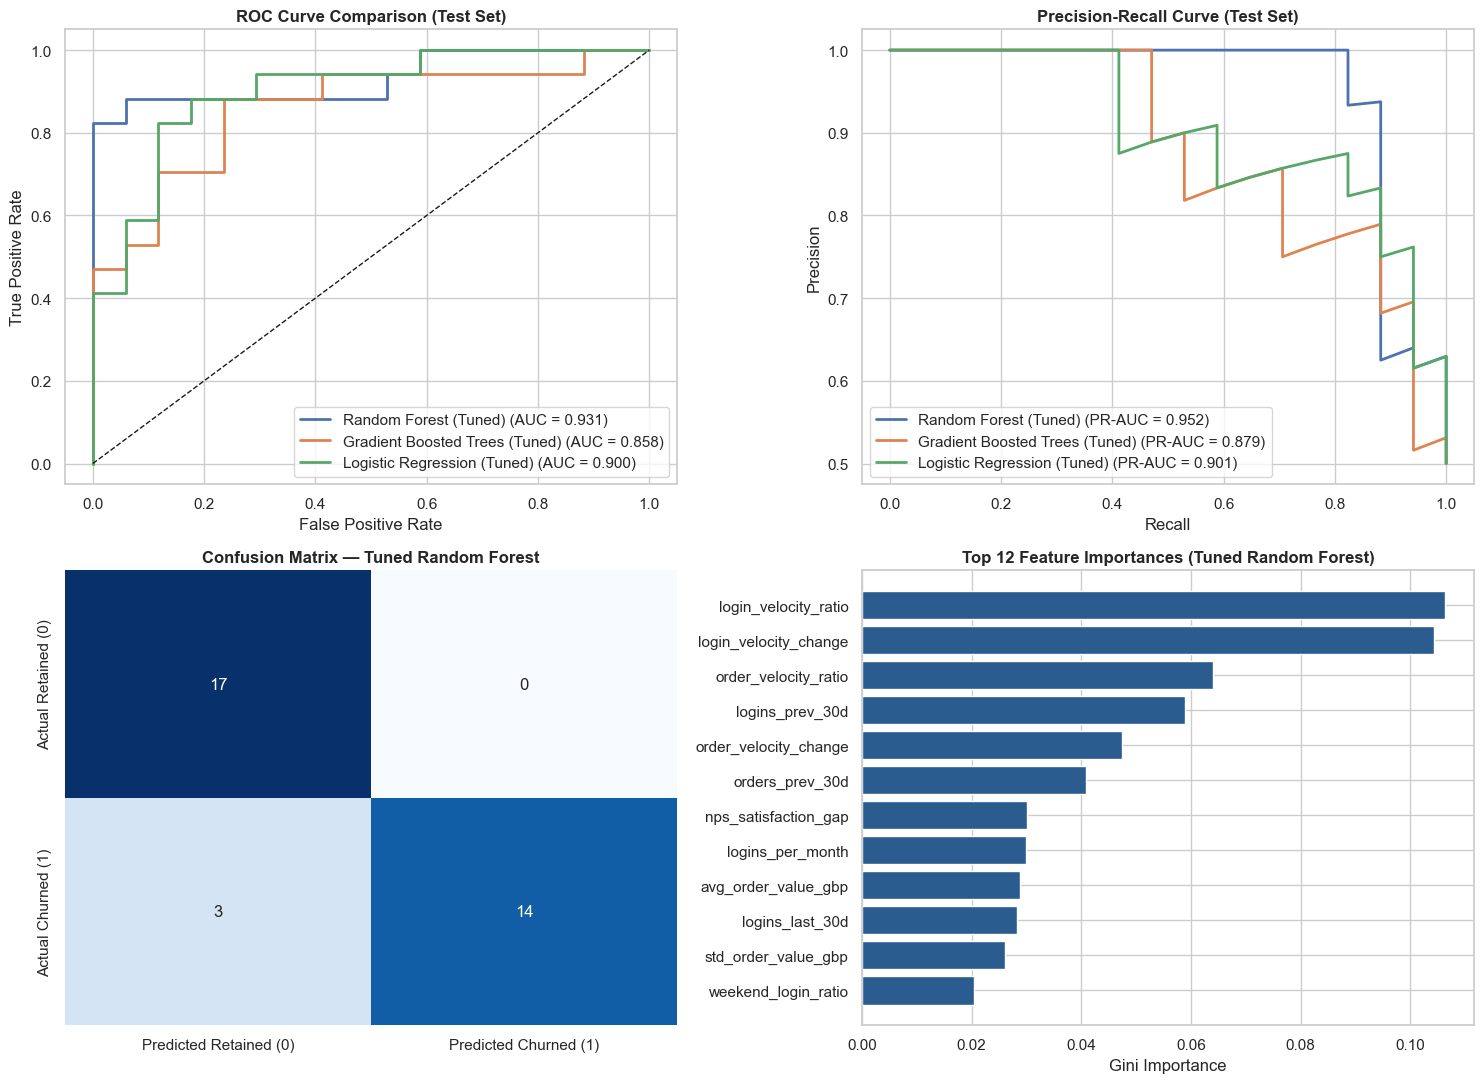


--- Classification Report (Tuned Random Forest) ---
              precision    recall  f1-score   support

Retained (0)       0.85      1.00      0.92        17
 Churned (1)       1.00      0.82      0.90        17

    accuracy                           0.91        34
   macro avg       0.93      0.91      0.91        34
weighted avg       0.92      0.91      0.91        34



In [13]:
def get_assembled_feature_names(fitted_pipeline_model) -> list:
    """Extracts expanded feature names after OneHotEncoding and VectorAssembler."""
    transformed_sample = fitted_pipeline_model.transform(test_df.limit(1))
    meta = transformed_sample.schema["raw_features"].metadata["ml_attr"]["attrs"]
    attrs = []
    for attr_type in meta.values():
        attrs.extend(attr_type)
    attrs = sorted(attrs, key=lambda x: x["idx"])
    return [a["name"] for a in attrs]


feature_names = get_assembled_feature_names(rf_cv_model.bestModel)
importances = rf_cv_model.bestModel.stages[-1].featureImportances.toArray()
feat_imp_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)
display(feat_imp_df.head(15))

def extract_probs_and_labels(pred_df):
    pdf = pred_df.select("churn", "prediction", "probability").toPandas()
    y_true = pdf["churn"].values
    y_pred = pdf["prediction"].values
    y_prob = np.array([float(v[1]) for v in pdf["probability"]])
    return y_true, y_pred, y_prob

y_true_rf, y_pred_rf, y_prob_rf = extract_probs_and_labels(rf_tuned_preds)
y_true_gbt, _, y_prob_gbt = extract_probs_and_labels(gbt_tuned_preds)
y_true_lr, _, y_prob_lr = extract_probs_and_labels(lr_tuned_preds)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for label, yt, yp in [
    ("Random Forest (Tuned)", y_true_rf, y_prob_rf),
    ("Gradient Boosted Trees (Tuned)", y_true_gbt, y_prob_gbt),
    ("Logistic Regression (Tuned)", y_true_lr, y_prob_lr)
]:
    fpr, tpr, _ = roc_curve(yt, yp)
    axes[0, 0].plot(fpr, tpr, lw=2, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
axes[0, 0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0, 0].set_title("ROC Curve Comparison (Test Set)", fontweight="bold")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend(loc="lower right")

for label, yt, yp in [
    ("Random Forest (Tuned)", y_true_rf, y_prob_rf),
    ("Gradient Boosted Trees (Tuned)", y_true_gbt, y_prob_gbt),
    ("Logistic Regression (Tuned)", y_true_lr, y_prob_lr)
]:
    prec, rec, _ = precision_recall_curve(yt, yp)
    axes[0, 1].plot(rec, prec, lw=2, label=f"{label} (PR-AUC = {auc(rec, prec):.3f})")
axes[0, 1].set_title("Precision-Recall Curve (Test Set)", fontweight="bold")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend(loc="lower left")

cm = confusion_matrix(y_true_rf, y_pred_rf)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, 0],
    xticklabels=["Predicted Retained (0)", "Predicted Churned (1)"],
    yticklabels=["Actual Retained (0)", "Actual Churned (1)"]
)
axes[1, 0].set_title("Confusion Matrix — Tuned Random Forest", fontweight="bold")

top12 = feat_imp_df.head(12).iloc[::-1]
axes[1, 1].barh(top12["Feature"], top12["Importance"], color="#2b5c8f")
axes[1, 1].set_title("Top 12 Feature Importances (Tuned Random Forest)", fontweight="bold")
axes[1, 1].set_xlabel("Gini Importance")

plt.tight_layout()
plt.show()

print("\n--- Classification Report (Tuned Random Forest) ---")
print(classification_report(y_true_rf, y_pred_rf, target_names=["Retained (0)", "Churned (1)"]))

## 8. Customer Prediction and Retention Risk Classification

Use the selected model to generate predictions for customer records.

Classify customers into different risk categories based on the
prediction results.

These predictions can help identify customers who may require
additional attention or targeted retention strategies.

In [14]:
from pyspark.ml.functions import vector_to_array

scored_all = (
    rf_cv_model.bestModel.transform(df_weighted)
    .withColumn("churn_probability", F.round(vector_to_array("probability")[1], 4))
    .withColumn(
        "retention_risk_tier",
        F.when(F.col("churn_probability") >= 0.65, "High Risk")
         .when(F.col("churn_probability") >= 0.40, "Medium Risk")
         .otherwise("Low Risk")
    )
)

scored_all.groupBy("retention_risk_tier", "churn").count().orderBy("retention_risk_tier", "churn").show()

print("Top 10 Highest-Risk Customers for Proactive Retention Outreach:")
(
    scored_all.select(
        "customer_id", "name", "email", "subscription_tier",
        "login_velocity_change", "order_velocity_change",
        "complaints_per_month", "churn_probability", "retention_risk_tier", "churn"
    )
    .orderBy(F.desc("churn_probability"))
    .show(10, truncate=False)
)

spark.stop()
logger.info("SparkSession stopped cleanly.")

+-------------------+-----+-----+
|retention_risk_tier|churn|count|
+-------------------+-----+-----+
|          High Risk|    1|   68|
|           Low Risk|    0|  131|
|           Low Risk|    1|    2|
|        Medium Risk|    0|    4|
|        Medium Risk|    1|   16|
+-------------------+-----+-----+

Top 10 Highest-Risk Customers for Proactive Retention Outreach:


2026-11-12 14:01:10 | INFO     | SparkSession stopped cleanly.


+-----------+-----------------+---------------------------------+-----------------+---------------------+---------------------+--------------------+-----------------+-------------------+-----+
|customer_id|name             |email                            |subscription_tier|login_velocity_change|order_velocity_change|complaints_per_month|churn_probability|retention_risk_tier|churn|
+-----------+-----------------+---------------------------------+-----------------+---------------------+---------------------+--------------------+-----------------+-------------------+-----+
|54         |Emmanuel Mensah  |Emmanuel365@somemail.co.uk       |SuperSaver       |-97                  |-17                  |1.0                 |0.9823           |High Risk          |1    |
|41         |Joseph Martin    |igi366@fakemail.co.uk            |Basic            |-75                  |-25                  |2.3333333333333335  |0.9723           |High Risk          |1    |
|90         |Amara Kamara     |A.Ka